# 01 Data Inspection (Sinhala)

Look at the raw scans: count, dpi, page orientation, missing/wrong passages, bad scans. Nothing is changed here.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

Image.MAX_IMAGE_PIXELS = None          # scans are ~35 MP; stops PIL's size warning

SINHALA = Path.cwd().parents[1]        # notebook runs from Sinhala/notebooks/01_preprocessing
RAW_DIR = SINHALA / "data" / "01_raw"
OUT_DIR = SINHALA / "data" / "02_intermediate" / "01_inspection"   # inside data/ -> not pushed
OUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_N = 220
print(RAW_DIR, RAW_DIR.exists())

c:\Users\adeep\Desktop\FYP-Akshara\Akshara\Research\Sinhala\data\01_raw True


## Are all Ids there

In [2]:
files = sorted(RAW_DIR.glob("SI-*.png"))
nums  = [int(re.fullmatch(r"SI-(\d{3})", f.stem).group(1)) for f in files]

missing = sorted(set(range(1, EXPECTED_N + 1)) - set(nums))
extra   = sorted(n for n in nums if n > EXPECTED_N)
print(f"files: {len(files)} | missing: {missing} | extra: {extra}")

files: 220 | missing: [] | extra: []


## Read File Header Data

In [ ]:
rows = []
for f in files:
    with Image.open(f) as im:
        dpi = im.info.get("dpi", (None, None))[0]
        rows.append({"id": f.stem, "width": im.width, "height": im.height, "mode": im.mode,
                     "dpi": round(dpi) if dpi else None, "mb": round(f.stat().st_size / 1e6, 1)})
facts = pd.DataFrame(rows).set_index("id")
facts[["width", "height", "mode", "dpi"]].value_counts()
print(facts)
# Check for DPI 

        width  height mode  dpi    mb
id                                   
SI-001   4960    7015  RGB  600   8.1
SI-002   4960    7015  RGB  600   8.6
SI-003   4960    7015  RGB  600  10.0
SI-004   4960    7015  RGB  600   9.4
SI-005   4960    7015  RGB  600   9.1
...       ...     ...  ...  ...   ...
SI-216   4960    7015  RGB  600   7.6
SI-217   4960    7015  RGB  600   8.3
SI-218   4960    7015  RGB  600   8.3
SI-219   4960    7015  RGB  600   9.1
SI-220   4960    7015  RGB  600  10.2

[220 rows x 5 columns]


## Step 4: Measure one page

We measure every page on a **4× smaller copy** (1240×1754 instead of 4960×7015). That's plenty for page-level checks and 16× faster.
Regions are given as **fractions of the page** `(x0, y0, x1, y1)`, so `(0.05, 0.10, 0.95, 0.28)` means "5–95% across, 10–28% down". This works at any image size.

**1. Page skew (`skew_deg`)**
- We use the **printed passage** (`PRINT_BOX`), not the handwriting. Printed lines are perfectly straight, so any tilt there comes from how the page sat on the scanner, not from the writer.
- Method: rotate the region from −3° to +3° in 0.25° steps. At the right angle, the text rows line up, so dark pixels pile into sharp row peaks. We keep the angle with the sharpest peaks (the highest variance of the row sums).

**2. Form layout (`writing_box_top`, `layout`)**
- Straighten the page, then find the **top border of the writing box**: the last long horizontal line between 25% and 42% of the page height.
- Its position tells us which printed form was used:

| Layout | Box top | Box covers |
|---|---|---|
| A | ≈ 0.29 | 29–88% of page height |
| B | ≈ 0.31 | 31–93% |
| C | ≈ 0.36 | 36–94% (older form) |

- Notebook 02 needs this, because each layout needs its own template.

**3. Handwriting measures (inside the writing box)**
- `area` sits just inside the box for every layout, so printed text and box lines aren't counted.
- `ink_%`: the share of dark pixels (gray < 160), which is roughly how much the person wrote. Very low or very high values get flagged.
- `ink_b_minus_r`: blue minus red for ink pixels. Blue pen → large positive (~30+); black pen → about 0. Used to label `ink_colour`.

**4. Output**
- A dict of measures for the table, plus a tiny thumbnail for the contact sheets.
- The last line tests the function on the first page before we run all 220.


In [5]:
PRINT_BOX = (0.05, 0.10, 0.95, 0.28)   # printed passage (page fractions x0, y0, x1, y1)

def crop_frac(a, box):
    h, w = a.shape[:2]
    x0, y0, x1, y1 = box
    return a[int(h*y0):int(h*y1), int(w*x0):int(w*x1)]

def skew_deg(gray, angles=np.arange(-3, 3.01, 0.25)):
    """Page skew: the rotation that makes the printed text rows sharpest."""
    region = Image.fromarray(crop_frac(gray, PRINT_BOX))
    scores = [(np.asarray(region.rotate(a, fillcolor=255)) < 128).sum(axis=1).var() for a in angles]
    return float(angles[int(np.argmax(scores))])

def writing_box_top(gray, skew):
    """Top border of the writing box = last long horizontal line between 25% and 42% of page height."""
    g = np.asarray(Image.fromarray(gray).rotate(skew, fillcolor=255))
    h, w = g.shape
    dark_frac = (g[:, int(w*0.15):int(w*0.85)] < 200).mean(axis=1)
    ys = np.where(dark_frac > 0.5)[0] / h
    ys = ys[(ys > 0.25) & (ys < 0.42)]
    return round(float(ys.max()), 3) if len(ys) else None

def layout(top):
    if top is None: return "unknown"
    return "C" if top > 0.33 else ("B" if top > 0.30 else "A")

def measure(path):
    with Image.open(path) as im:
        rgb = im.convert("RGB").reduce(4)            # 4960x7015 -> 1240x1754
    gray = np.asarray(rgb.convert("L"))
    skew = skew_deg(gray)
    top  = writing_box_top(gray, skew)

    area = (0.10, (top or 0.37) + 0.01, 0.88, 0.87)  # inside the writing box for every layout
    w_rgb  = crop_frac(np.asarray(rgb).astype(np.int16), area)
    ink    = crop_frac(gray, area) < 160             # dark pixels = handwriting
    b_minus_r = (w_rgb[..., 2] - w_rgb[..., 0])[ink] # blue ink: blue channel much higher than red

    vals = {"skew_deg": skew, "box_top": top, "layout": layout(top),
            "ink_%": round(100 * ink.mean(), 2),
            "ink_b_minus_r": float(np.median(b_minus_r)) if ink.any() else np.nan}
    return vals, rgb.reduce(4)                       # small thumbnail for the contact sheets

measure(files[0])[0]

{'skew_deg': 0.25,
 'box_top': 0.362,
 'layout': 'C',
 'ink_%': np.float64(4.66),
 'ink_b_minus_r': 103.0}

In [6]:
measures, thumbs = [], {}
for i, f in enumerate(files, 1):
    vals, thumbs[f.stem] = measure(f)
    measures.append({"id": f.stem, **vals})
    if i % 20 == 0:
        print(f"{i}/{len(files)}")

df = facts.join(pd.DataFrame(measures).set_index("id"))
df["ink_colour"] = np.where(df.ink_b_minus_r > 25, "blue", "black")
print(df.layout.value_counts(), "\n")
print(df.ink_colour.value_counts())

20/220
40/220
60/220
80/220
100/220
120/220
140/220
160/220
180/220
200/220
220/220
layout
A    162
B     33
C     25
Name: count, dtype: int64 

ink_colour
blue     208
black     12
Name: count, dtype: int64


In [8]:
rules = {
    "not_600dpi":  df.dpi != 600,
    "odd_size":    (df.width != df.width.mode()[0]) | (df.height != df.height.mode()[0]),
    "skew_>1deg":  df.skew_deg.abs() > 1,
    "layout?":     df.layout == "unknown",
    "little_ink":  df["ink_%"] < df["ink_%"].quantile(0.02),
    "lots_of_ink": df["ink_%"] > df["ink_%"].quantile(0.98),
}
df["qc_flags"] = pd.DataFrame(rules).apply(lambda r: ", ".join(k for k, v in r.items() if v), axis=1)

NOTES = {}
df["notes"] = df.index.map(NOTES).fillna("")

df.to_csv(OUT_DIR / "inspection.csv")
df[(df.qc_flags != "") | (df.notes != "")][["skew_deg", "layout", "ink_%", "ink_colour", "qc_flags", "notes"]]

C:\Users\adeep\AppData\Local\Temp\ipykernel_26644\2694806819.py:12: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df["notes"] = df.index.map(NOTES).fillna("")


,skew_deg,layout,ink_%,ink_colour,qc_flags,notes
id,,,,,,
SI-003,0.25,C,9.17,blue,lots_of_ink,
SI-008,0.75,C,12.46,black,lots_of_ink,
SI-012,0.50,C,9.60,blue,lots_of_ink,
SI-017,1.25,C,6.10,blue,skew_>1deg,
SI-018,0.50,C,9.55,blue,lots_of_ink,
SI-022,2.25,C,2.36,blue,"skew_>1deg, little_ink",
SI-031,1.75,A,4.09,blue,skew_>1deg,
SI-038,1.50,B,3.96,blue,skew_>1deg,
SI-097,1.50,A,3.35,blue,skew_>1deg,


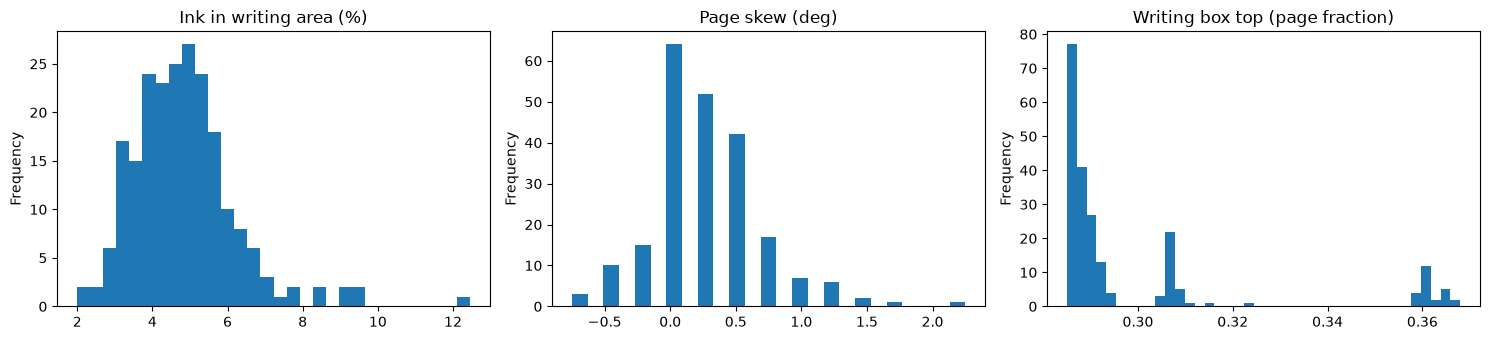

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
df["ink_%"].plot.hist(bins=30, ax=ax[0], title="Ink in writing area (%)")
df.skew_deg.plot.hist(bins=25, ax=ax[1], title="Page skew (deg)")
df.box_top.plot.hist(bins=40, ax=ax[2], title="Writing box top (page fraction)")
plt.tight_layout(); plt.show()

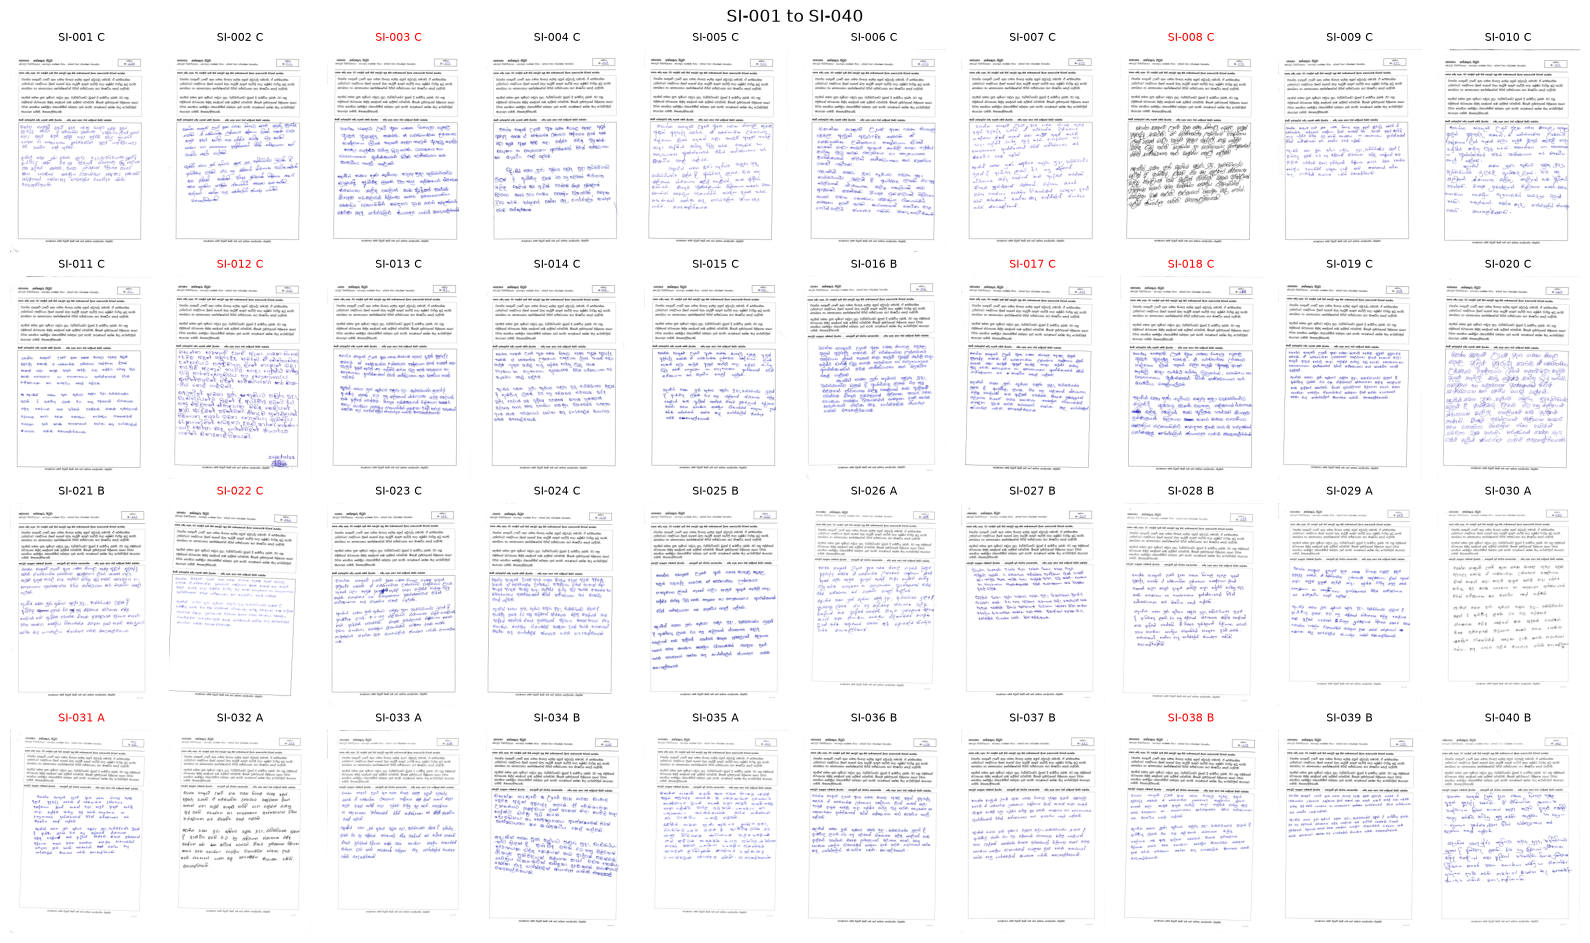

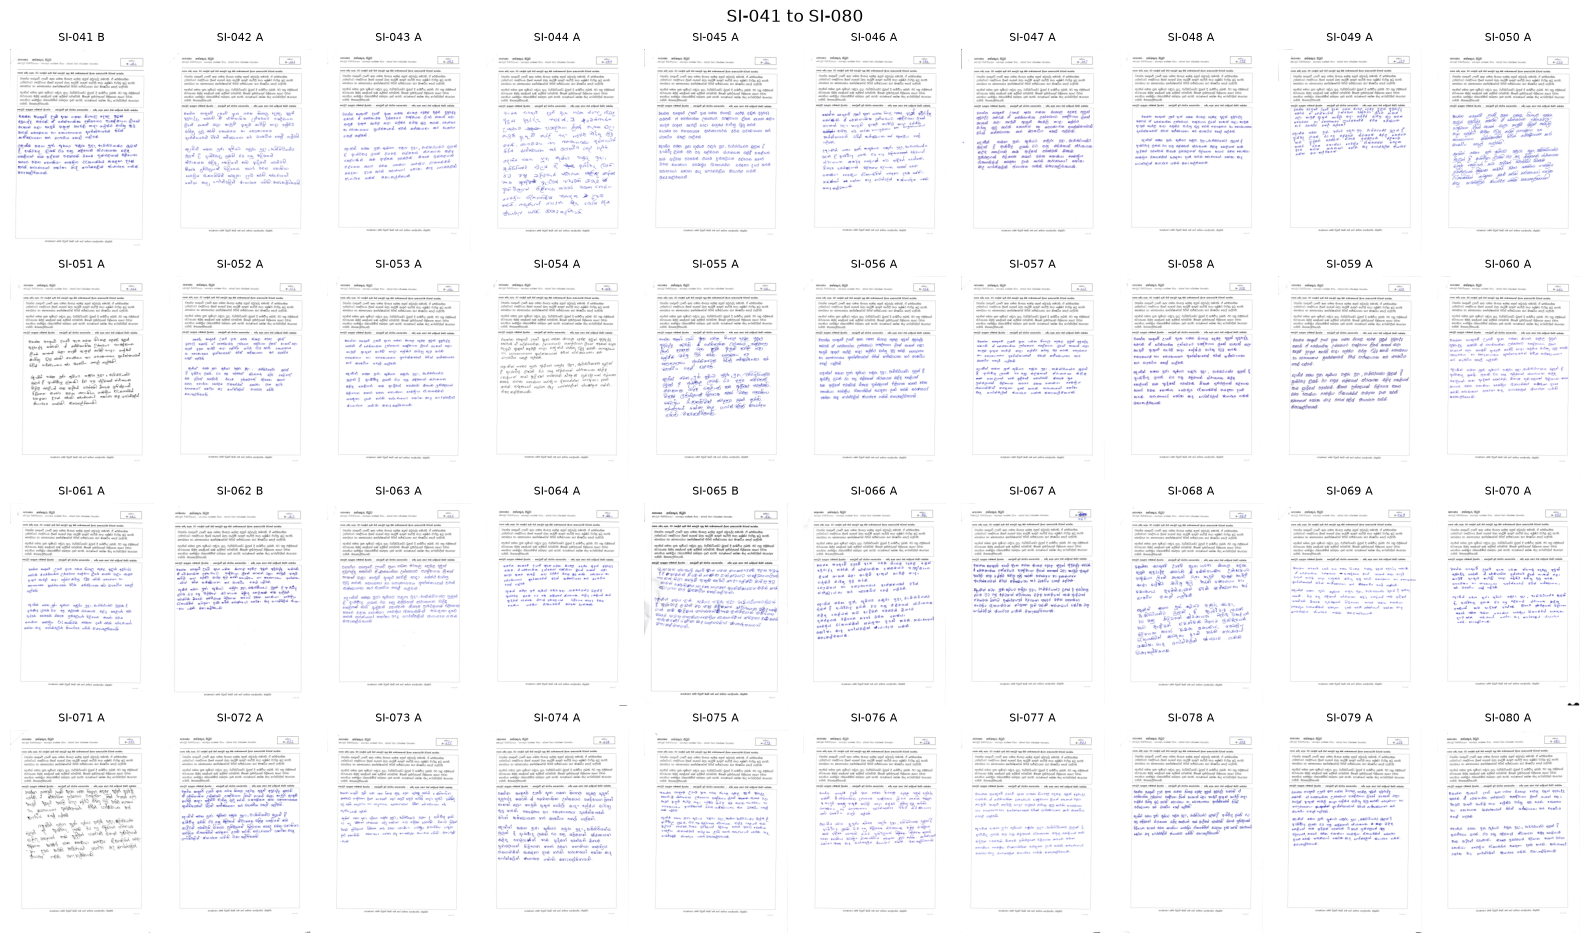

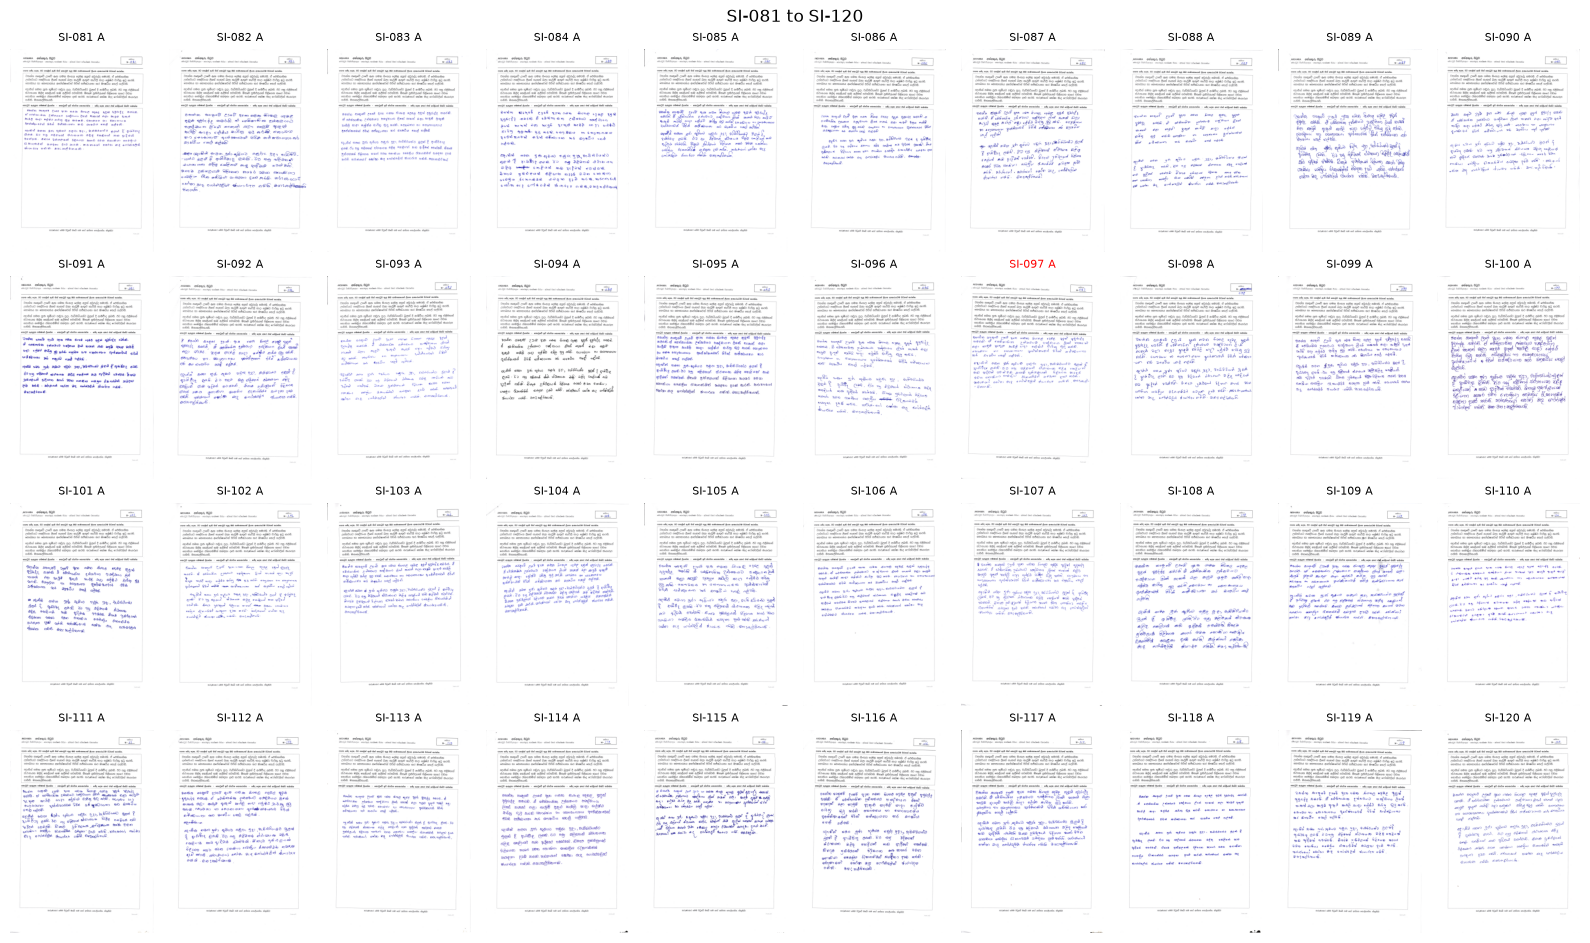

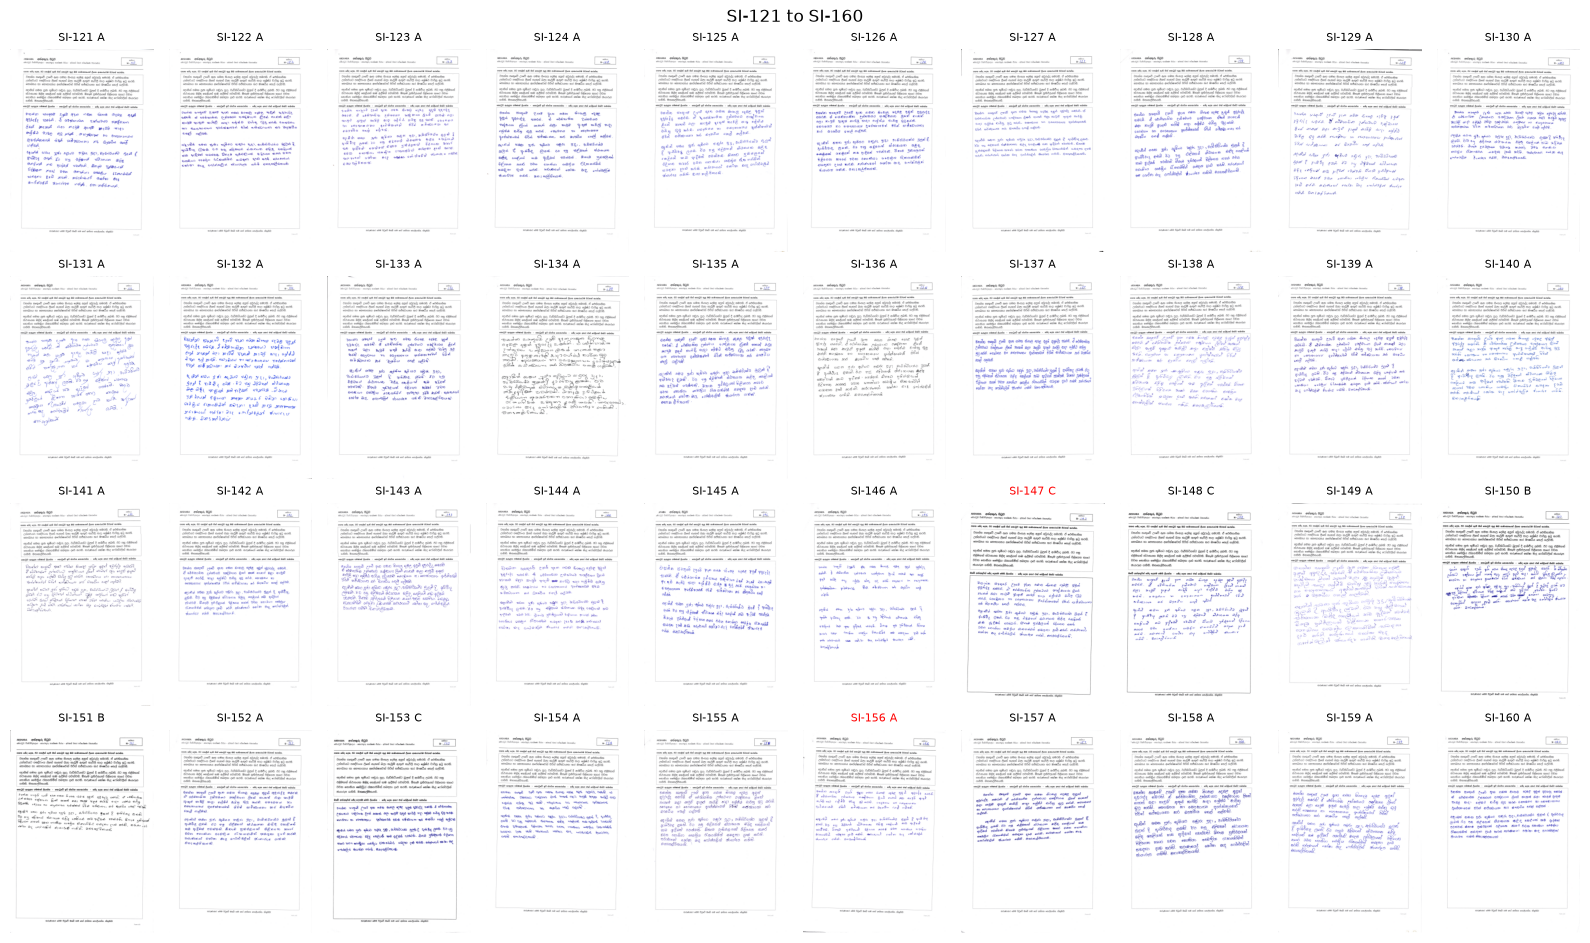

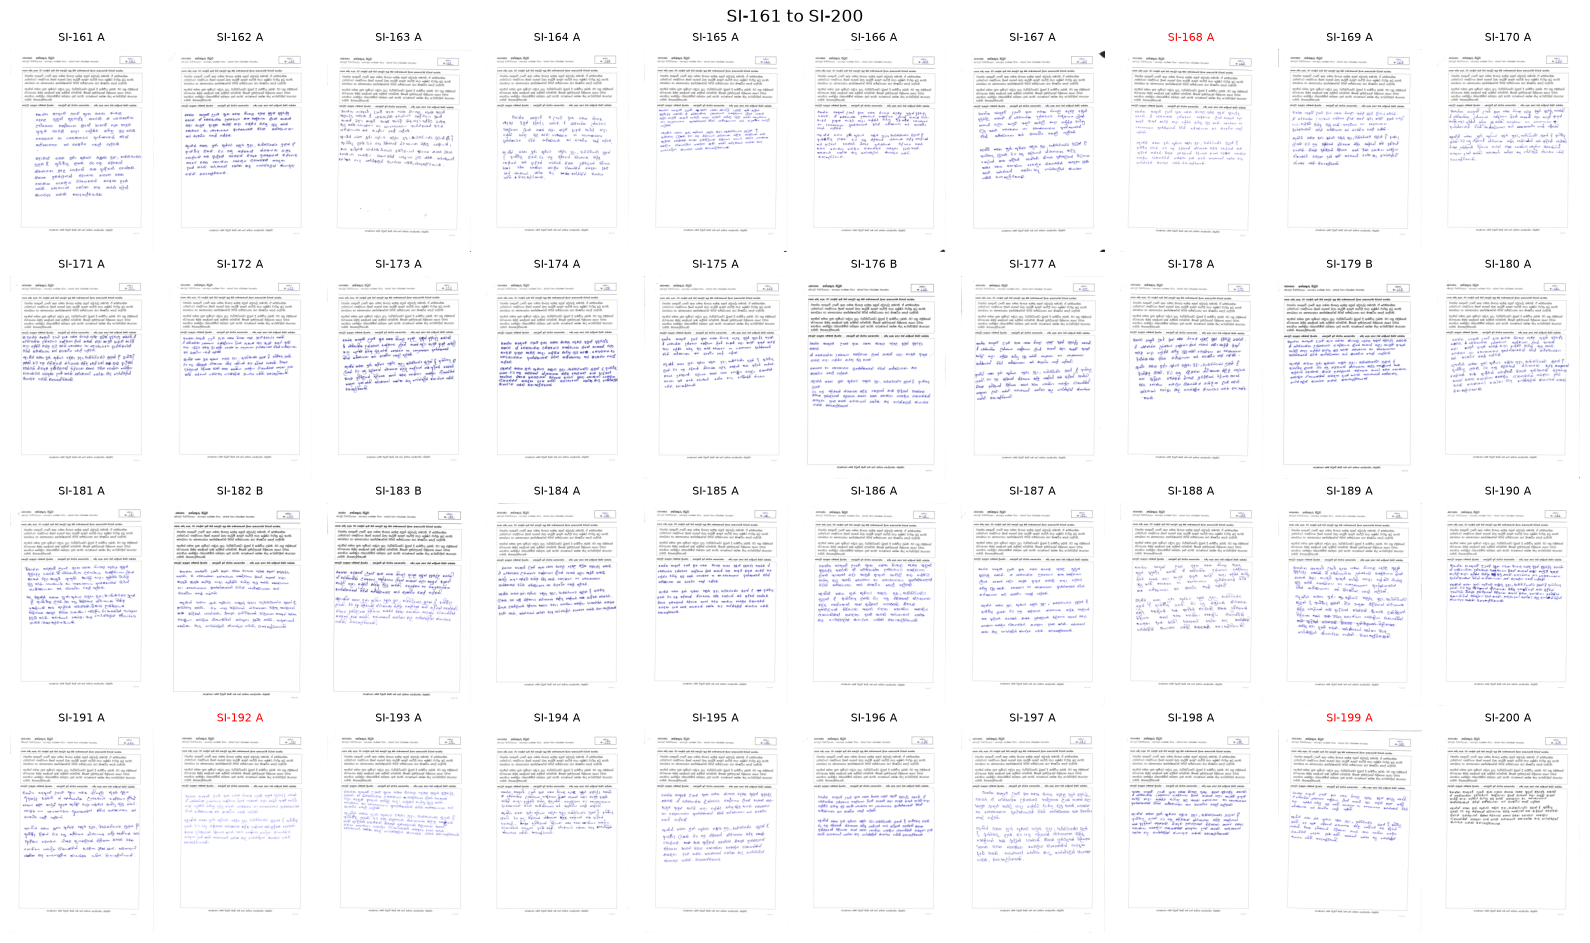

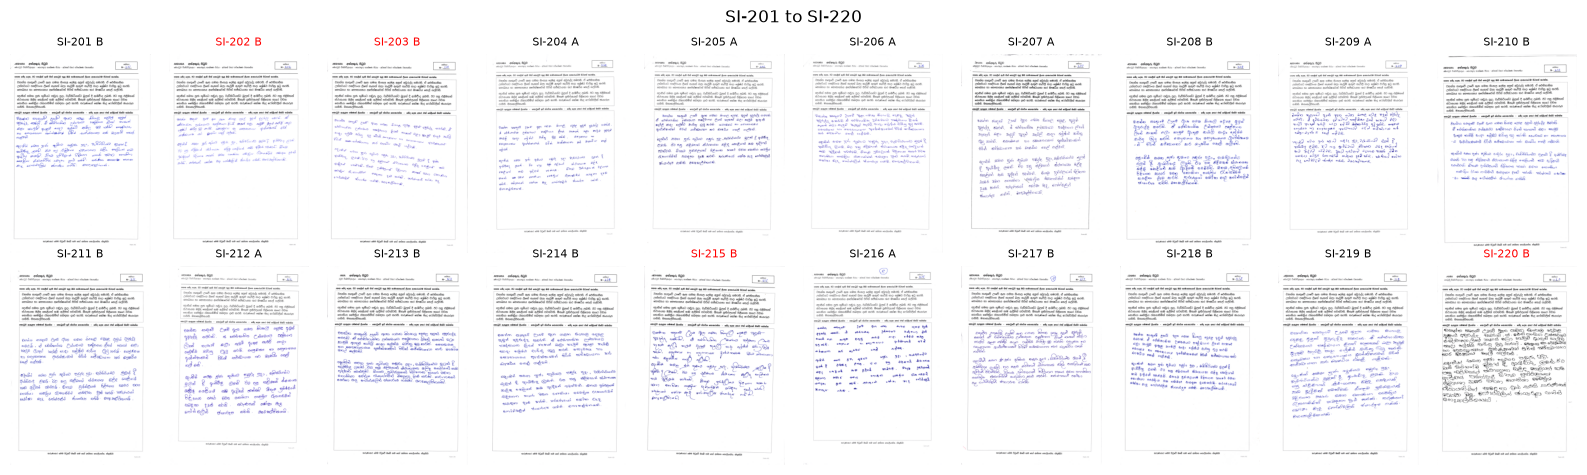

In [10]:
def contact_sheet(ids, cols=10, title=""):
    n_rows = int(np.ceil(len(ids) / cols))
    fig, axes = plt.subplots(n_rows, cols, figsize=(cols * 1.6, n_rows * 2.4))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, sid in zip(np.ravel(axes), ids):
        ax.imshow(thumbs[sid])
        red = df.loc[sid, "qc_flags"] or df.loc[sid, "notes"]
        ax.set_title(f"{sid} {df.loc[sid, 'layout']}", fontsize=8, color="red" if red else "black")
    fig.suptitle(title); plt.tight_layout()
    return fig

ids = list(df.index)
for s in range(0, len(ids), 40):
    chunk = ids[s:s + 40]
    fig = contact_sheet(chunk, title=f"{chunk[0]} to {chunk[-1]}")
    fig.savefig(OUT_DIR / f"contact_{chunk[0]}_{chunk[-1]}.png", dpi=100)
    plt.show()

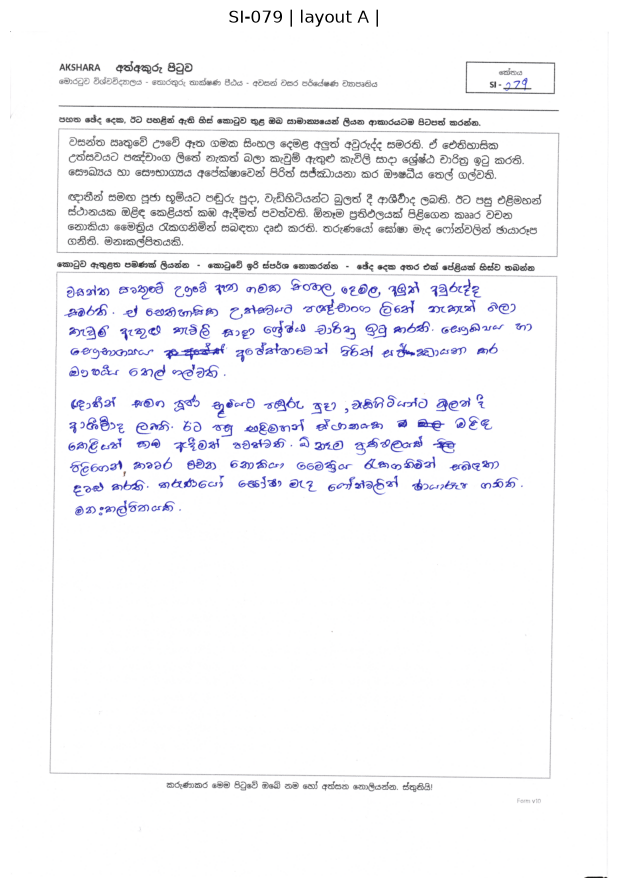

In [11]:
def show(sid):
    with Image.open(RAW_DIR / f"{sid}.png") as im:
        page = im.convert("RGB").reduce(4)
    plt.figure(figsize=(8, 11)); plt.imshow(page); plt.axis("off")
    plt.title(f"{sid} | layout {df.loc[sid, 'layout']} | {df.loc[sid, 'qc_flags']} {df.loc[sid, 'notes']}")
    plt.show()

show("SI-079")

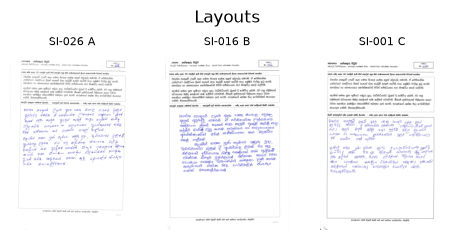

In [12]:
examples = [df.index[df.layout == L][0] for L in sorted(df.layout.unique())]
contact_sheet(examples, cols=len(examples), title="Layouts")
plt.show()

## Summary: issues found and what to do

**Dataset check: OK**
- 220 scans (SI-001 to SI-220), none missing or extra. All 4960×7015, RGB, 600 dpi.
- Ink: 208 blue, 12 black. Layouts: A 162, B 33, C 25.
- ID problems found while renaming (SI-015/016, SI-079, SI-115) are fixed; see the README.

### Issues found

| # | Issue | Pages | Handled in |
|---|---|---|---|
| 1 | **Three printed form layouts.** C is an older form (different instruction line, writing box 36–94% of page height). A and B look like the same v10 form printed at different sizes (box 29–88% vs 31–93%). | C: SI-001–024 (except 016, 021), 147, 148, 153. B: 33 pages (`inspection.csv`). A: the rest | 02, analysis |
| 2 | **Page skew > 1°** | SI-017, 022, 031, 038, 097, 147, 156, 168, 199, 215 (max 2.25°, SI-022) | 02 |
| 3 | **Blue vs black ink** | Black: SI-008, 030, 032, 051, 054, 071, 094, 134, 136, 151, 200, 220 | 04, analysis |
| 4 | **Signature + date inside the writing box** | SI-012 | 03 |
| 5 | **Extreme ink amounts** (normal variation, not errors) | Little: SI-022, 168, 192, 202, 203. Lots: SI-003, 008, 012, 018, 220 | 03, 05 (test cases) |
| 6 | **Crossings-out** (keep: raters see them, the team counts them) | e.g. SI-018 | rubric |

### What to do

**02 Page registration**
- [ ] Make one clean template per layout (A, B, C): ideally a blank printed form scanned at 600 dpi.
- [ ] Align every page to its layout's template using rotation + scale + shift (not just shift).
- [ ] Check the result on SI-022 (most skewed) and one page from each layout.

**03 Handwriting extraction**
- [ ] Remove the printed text and box lines without losing thin or small strokes (test on SI-168, 192, 202, 203).
- [ ] Mask the signature and date on SI-012.

**04 Ink normalisation**
- [ ] Turn blue and black ink into one soft-black tone; check on a blue page and a black page (e.g. SI-008, SI-220).

**05 Paragraph segmentation**
- [ ] Split the two paragraphs; test on dense pages (SI-003, 008, 012, 018, 220).

**Before rating**
- [ ] Look through the contact sheets for any other names or signatures and mask them.

**After rating (analysis)**
- [ ] Keep `layout` and `ink_colour` as columns; check whether ratings differ by layout or pen colour, and report it as a limitation if they do.

### Privacy
- Scans and contact sheets stay in `data/` (ignored by git).
- **Clear All Outputs before committing this notebook**: the outputs contain participants' handwriting.